# SIRUS: RuleFit'in kararsızlığına çözüm mü?
**Makale:** Bénard, Biau, Da Veiga, Scornet — *Interpretable Random Forests via Rule Extraction* (AISTATS 2021)

Ahmet Nail Arslan (20269348010) · Bölüm 11: RuleFit

**İzlence türü:** Seçenek 2 (Kıyaslama) + Seçenek 3 (Geliştirme/Modifikasyon)

**Hata = 1 − R² (test katları).**

**İddia:** RuleFit, veri biraz değişince bambaşka kurallar seçer. SIRUS rakiplerine yakın doğrulukla, çok daha az ve *kararlı* kural verir.

**Sorular:** İddia yeniden üretilebiliyor mu? Kendi verimizde (Bike Sharing) geçerli mi? SIRUS nerede kırılıyor?

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import Image, display
import calistir, figurler
from sirus_py import *
from veri_yukle import yukle
pd.set_option("display.max_colwidth", 70)

YENIDEN_CALISTIR = False   # True: bütün deneyi baştan çalıştırır (28 süreçle ~40 dk; .onbellek varsa hızlı)
if YENIDEN_CALISTIR:
    calistir.calistir()

## 1. Kararsızlığı gözle görelim
Bike verisinin iki farklı %90'lık alt örneğine aynı algoritmayı uyarlıyoruz. Kaç kural ortak?

Ölçü, **Dice-Sørensen** indeksi: $2|A\cap B| / (|A|+|B|)$. 1 = aynı liste, 0 = hiç ortak kural yok.
(Canlı gösterimde R gerektirmeyen imodels RuleFit kullanılıyor; asıl karşılaştırma aşağıda `pre` ile.)

In [2]:
calistir.kararsizlik()

,yöntem,kural_1,kural_2,ortak,dice
0,SIRUS,7,9,6,0.75
1,RuleFit (imodels),79,79,11,0.14


**Neden?** RuleFit yüzlerce, birbiriyle güçlü ilişkili kuralı Lasso'ya verir. Lasso, neredeyse aynı iki kuraldan birini
keyfî seçer; veri biraz değişince seçim değişir.

## 2. SIRUS nasıl çalışır?
1. **Kural üretimi:** Bölünmeler 10 kantille sınırlı, derinliği 2 olan binlerce ağaçlık rastgele orman. Her düğüm bir kuraldır.
2. **Kural seçimi:** Kuralın görüldüğü ağaç oranı $\hat p(P) > p_0$ ise kural kalır. *Tahminler değil, kuralların kendisi oylanır.*
3. **Son işlem:** Daha sık kuralların doğrusal birleşimi olan kural atılır.
4. **Birleştirme:** Ağırlıkları $\beta\ge 0$ kısıtlı ridge regresyonu (Lasso değil).

In [3]:
# 1. adım: küçük bir ormanda en sık görülen kurallar (Machine verisi)
X, y, _ = yukle("Machine")
kutu = Kutulayici().fit(X)
frek, agac = kural_frekanslari(kutu.transform(X), y, agac=1000)
m0 = SIRUS(); m0.kutu = kutu
pd.DataFrame([(round(frek[r], 3), m0.yaz(r, list(X.columns))) for r in sirala(frek)[:8]], columns=["sıklık", "kural"])

,sıklık,kural
0,0.306,MMAX < 3.2e+04
1,0.306,MMAX >= 3.2e+04
2,0.238,MMIN < 8000
3,0.238,MMIN >= 8000
4,0.150,CACH < 64
5,0.150,CACH >= 64
6,0.145,CHMIN < 8
7,0.145,CHMIN >= 8


`MMAX < 32000` ile `MMAX >= 32000` aynı sıklıkta: bir kökün iki çocuğu. "DEĞİLSE" kısmıyla birlikte aynı kuraldırlar.
Son işlem bu fazlalığı siler. Makaledeki **Tablo 6** bunun birebir testi: 17 ham kural → 9 kural.

In [4]:
# Tablo 6'nın 17 ham kuralı; öznitelik: MMAX=0 MMIN=1 CACH=2 CHMIN=3 MYCT=4 (kesimler simgesel)
T6 = [((0,8,0),), ((0,8,1),), ((1,8,0),), ((1,8,1),), ((2,8,0),), ((2,8,1),), ((0,8,1),(2,8,1)), ((3,6,0),),
      ((3,6,1),), ((4,2,0),), ((4,2,1),), ((0,8,1),(2,8,0)), ((0,8,0),(3,6,1)), ((0,8,1),(3,8,1)),
      ((0,8,1),(3,8,0)), ((1,8,1),(3,8,1)), ((1,8,1),(3,8,0))]
kalan = [T6.index(r) + 1 for r in son_islem(T6)]
print("Makale:", [1, 3, 5, 7, 8, 10, 13, 14, 16]); print("Bizim :", kalan)
assert kalan == [1, 3, 5, 7, 8, 10, 13, 14, 16]

Makale: [1, 3, 5, 7, 8, 10, 13, 14, 16]
Bizim : [1, 3, 5, 7, 8, 10, 13, 14, 16]


> **Makalede olası dizgi hatası:** Tablo 6'da 14. kural `MMAX < 32000 & CHMIN >= 12 → 554` basılmış. Veride 554 değerini
> `MMAX >= 32000` verir (aşağıdaki liste). Testte bu düzeltilmiş yön kullanıldı; basılı yönle 15. kural da kalıyor.

In [5]:
m, b0, g = figurler.kural_listesi("Machine", 0.072)   # p0 = 0.072: makale, Ek Bölüm 4
print(f"{m.M} ağaç, {len(g)} kural (Tablo 6: 9 kural)"); g.round(3)

5000 ağaç, 9 kural (Tablo 6: 9 kural)


,sıklık,kural,İSE,DEĞİLSE,ağırlık
0,0.305,EĞER MMAX < 3.2e+04,60.725,408.259,0.176
1,0.227,EĞER MMIN < 8000,62.287,385.750,0.108
2,0.150,EĞER CACH < 64,56.395,334.459,0.198
3,0.141,EĞER MMAX >= 3.2e+04 & CACH >= 64,516.611,66.890,0.177
4,0.137,EĞER CHMIN < 8,50.485,312.386,0.157
5,0.120,EĞER MYCT < 50,335.000,57.890,0.164
6,0.102,EĞER MMAX < 3.2e+04 & CHMIN >= 8,157.143,99.867,0.013
7,0.094,EĞER MMAX >= 3.2e+04 & CHMIN >= 12,553.643,73.456,0.202
8,0.088,EĞER MMIN >= 8000 & CHMIN >= 12,585.583,76.386,0.213


## 3. Tablo 1: LA Ozone kural listesi
Makaledeki sıklıklar (Tablo 1, s. 5) ile yan yana:

In [6]:
m, b0, g = figurler.kural_listesi("Ozone", 0.038)
makale = {"temp < 65.4": .29, "ibt < 189": .17, "temp >= 65.4 & vis < 150": .063, "vh < 5840": .061, "ibh < 2112": .060,
          "ibh < 2958": .058, "temp >= 65.4 & ibh < 2112": .051, "vis < 150": .048, "temp < 65.4 & ibt < 119.7": .043,
          "temp < 70": .040, "ibt < 227.2": .039}          # eşikler makalede yuvarlanmış: 65, 2110, 2960, 120, 227
g.insert(1, "makale sıklık", [makale.get(k.replace("EĞER ", "")) for k in g.kural])
print(f"{m.M} ağaç (makale: yaklaşık 9000)"); g.round(3)

11000 ağaç (makale: yaklaşık 9000)


,sıklık,makale sıklık,kural,İSE,DEĞİLSE,ağırlık
0,0.286,0.290,EĞER temp < 65.4,6.975,18.977,0.087
1,0.175,0.170,EĞER ibt < 189,7.360,18.316,0.049
2,0.064,0.063,EĞER temp >= 65.4 & vis < 150,20.254,7.301,0.356
3,0.062,0.061,EĞER vh < 5840,9.512,20.186,0.059
4,0.061,0.058,EĞER ibh < 2958,15.409,6.326,0.088
5,0.057,0.060,EĞER ibh < 2112,16.206,7.345,0.156
6,0.051,0.051,EĞER temp >= 65.4 & ibh < 2112,20.887,7.983,0.154
7,0.049,0.048,EĞER vis < 150,14.178,6.629,0.198
8,0.042,0.043,EĞER temp < 65.4 & ibt < 119.7,5.093,14.558,0.169
9,0.041,0.040,EĞER temp < 70,7.982,20.255,0.146


11 kuralın tamamı aynı. p0=0.038, makaledeki en düşük sıklığın (0.039) hemen altı olduğu için seçildi.
Ağırlıklar birebir değil: λ'nın çapraz doğrulama katları rastgele, kurallar da birbiriyle ilişkili.

## 4. Ana bulgu: kararlılık (Tablo 2b)
8 veri seti, 10 tekrar × 10 kat (Abalone'da RuleFit 3 tekrar). Hesap `calistir.py` ile yapıldı; burada kayıtlı sonuç okunuyor.
**M** = makale, **YÜ** = yeniden üretim.

In [7]:
kar, say, hata = figurler.karsilastirma()
kar

,RuleFit M,pre YÜ,imodels YÜ,SIRUS M,SIRUS YÜ,SIRUS-eşli YÜ
Ozone,0.22,0.30,0.08,0.62,0.78,0.58
Mpg,0.25,0.29,0.10,0.77,0.79,0.78
Prostate,0.32,0.40,0.05,0.58,0.57,0.58
Housing,0.19,0.24,0.12,0.82,0.79,0.80
Diabetes,0.18,0.23,0.10,0.69,0.66,0.65
Machine,0.23,0.46,0.13,0.86,0.83,0.87
Abalone,0.31,0.32,0.10,0.75,0.75,0.71
Bones,0.59,0.58,0.15,0.96,0.93,0.93


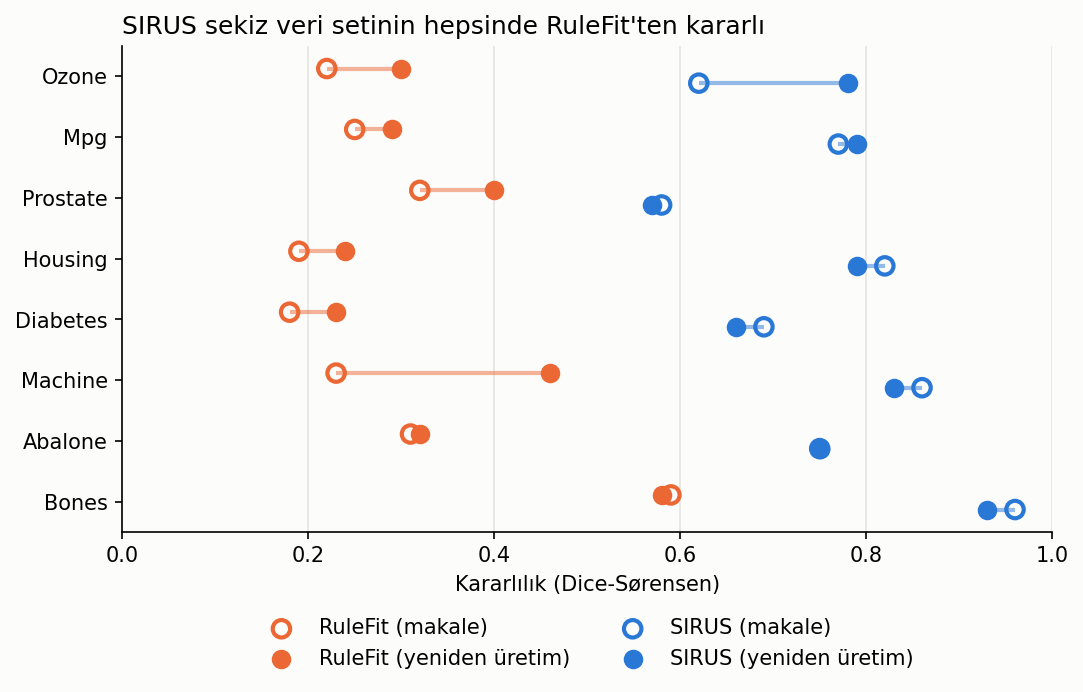

In [8]:
figurler.sekil1(); display(Image("sekiller/sekil1_kararlilik.png"))

**Sonuç:** Yön 8/8 yeniden üretildi.
- **SIRUS** yedi veri setinde makaleye 0.04 içinde. İstisna **Ozone**: p0 farklı seçildi (bkz. 6. bölüm). Kural sayısı makaledekine
  eşlenince 0.58 (makale 0.62). *SIRUS-eşli* sütunu makaleye göre ayarlıdır; bağımsız doğrulama değildir.
- **RuleFit (`pre`)** çoğunda makaleden biraz kararlı; en büyük fark Machine (0.46'ya karşı 0.23). Nedeni aşağıda.
- **imodels** RuleFit çok daha kararsız ve çok kurallı (≈60–180). Farklı bir uygulama olduğu için ana karşılaştırmaya alınmadı.

## 5. Bedeli: kural sayısı ve hata (Tablo 2a, Tablo 3)

### RuleFit'te kutulama etkisi
`pre` λ = `lambda.1se`, 500 ağaç, derinlik 3 (varsayılanlar). Kural kimliği kutulamasız: değişken + yön + ham eşik. Kutulu iki seçenek: soldan kapalı [a,b) ve sağdan kapalı (a,b] (R `cut()` varsayılanı).

In [9]:
figurler.pre_tablosu()

,makale,"kutulu [a,b)","kutulu (a,b]",kutulamasız,kural makale,kural (pre),kural (kutulamasız çalıştırma)
Ozone,0.22,0.30,0.29,0.07,21.0,29.48,28.49
Mpg,0.25,0.29,0.31,0.10,40.0,54.49,55.25
Prostate,0.32,0.40,0.36,0.23,14.0,15.76,15.46
Housing,0.19,0.24,0.23,0.04,54.0,83.08,84.01
Diabetes,0.18,0.23,0.23,0.06,25.0,30.50,30.95
Machine,0.23,0.46,0.25,0.21,44.0,43.02,43.67
Abalone,0.31,0.32,0.35,0.05,58.0,124.97,122.77
Bones,0.59,0.58,0.56,0.31,5.0,14.43,14.39
Bike,NaN,0.26,0.28,0.04,NaN,81.07,82.09


**Machine açıklandı:** 0.46 → 0.25 (makale 0.23); fark kutunun hangi ucunun kapalı olduğundan. Kutulamasız hâl makalenin değeri değil (7 veride çok altında).

### Ozone: kısa ve uzun SIRUS listesi ayrı ayrı
Makale: hata 0.32, kararlılık 0.62, 11 kural.

In [10]:
figurler.ozone_tablosu()

,liste,secilen_tekrar,p0,hata,kararlilik,kural
0,kısa,6,0.104,0.422,0.833,2.40
1,uzun,4,0.036,0.329,0.597,9.52


In [11]:
say

,RuleFit M,pre YÜ,imodels YÜ,SIRUS M,SIRUS YÜ,SIRUS-eşli YÜ
Ozone,21,29.5,132.8,11,2.7,10.9
Mpg,40,54.5,119.0,10,10.3,10.0
Prostate,14,15.8,96.1,9,9.9,9.0
Housing,54,83.1,118.8,6,6.1,6.0
Diabetes,25,30.5,178.6,12,10.9,12.0
Machine,44,43.0,62.1,9,10.0,8.9
Abalone,58,125.0,165.1,8,7.1,8.1
Bones,5,14.4,131.4,1,1.1,1.0


In [12]:
hata

,RF M,RF YÜ,CART M,CART YÜ,RuleFit M,pre YÜ,imodels YÜ,SIRUS M,SIRUS YÜ,SIRUS-eşli YÜ
Ozone,0.25,0.25,0.36,0.39,0.27,0.27,0.38,0.32,0.42,0.32
Mpg,0.13,0.13,0.20,0.18,0.15,0.14,0.17,0.20,0.19,0.20
Prostate,0.48,0.47,0.60,0.66,0.53,0.53,0.86,0.55,0.56,0.57
Housing,0.13,0.13,0.28,0.26,0.16,0.16,0.15,0.30,0.31,0.31
Diabetes,0.55,0.54,0.67,0.66,0.55,0.56,0.88,0.56,0.56,0.56
Machine,0.13,0.16,0.39,0.32,0.26,0.25,0.13,0.29,0.30,0.30
Abalone,0.44,0.44,0.56,0.52,0.46,0.46,0.47,0.66,0.66,0.66
Bones,0.67,0.65,0.67,0.74,0.70,0.67,0.94,0.73,0.73,0.74


Kararlılık bedava değil. SIRUS'un hatası Housing (0.31'e karşı 0.16) ve Abalone'da (0.66'ya karşı 0.46) `pre`'den belirgin yüksek.
Makalenin kendi Tablo 3'ü de aynı farkı gösterir. Özet "rakipleriyle karşılaştırılabilir doğruluk" der, metin "RuleFit'in biraz altında"; bu iki veri setinde fark "biraz" değil.

## 6. Zafiyet 1: p0 seçiminin kendisi kararsız olabilir
p0, (hata 0, kararlılık 0.9) noktasına en yakın olan seçilerek bulunur.

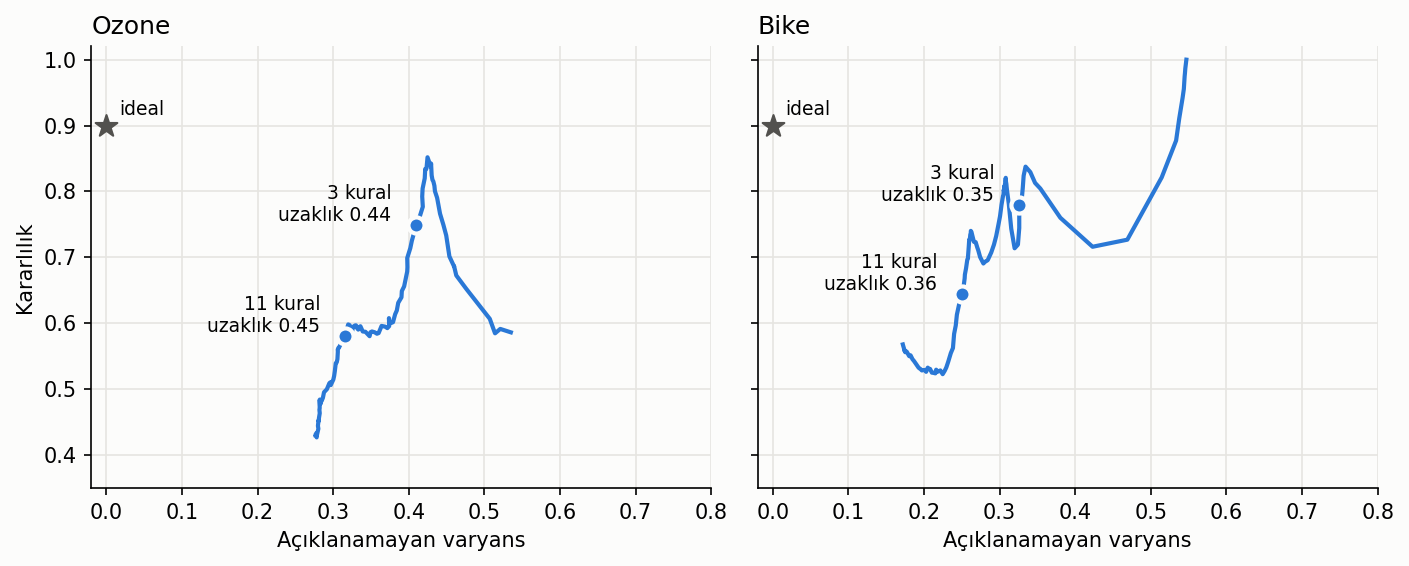

In [13]:
figurler.sekil2(); display(Image("sekiller/sekil2_p0.png"))

Ozone'da kısa (≈3) ve uzun (≈11) listelerin ideal noktaya uzaklığı birbirine çok yakın: 10 tekrarın 4'ünde p0 ≈ 0.035, 6'sında ≈ 0.1 seçildi.
Yani kurallar kararlı olsa da **listenin uzunluğu** rastgele katlara bağlı kalabiliyor.

## 7. Kendi verim: Bike Sharing

In [14]:
s = pd.read_csv(calistir.SONUC / "ana.csv")
s[s.veri == "Bike"].drop(columns=["veri", "p0"]).round(3).reset_index(drop=True)

,yontem,hata,kararlilik,kural
0,SIRUS,0.262,0.740,7.71
1,pre,0.112,0.261,81.07
2,imodels,0.165,0.119,136.76
3,CART,0.210,NaN,61.08
4,RF,0.124,NaN,NaN


In [15]:
p0 = s.query("veri=='Bike' and yontem=='SIRUS'").p0.iloc[0]
m, b0, g = figurler.kural_listesi("Bike", p0); g.round(3)

,sıklık,kural,İSE,DEĞİLSE,ağırlık
0,0.188,EĞER temp < 12.15,3063.469,5483.661,0.279
1,0.144,EĞER cnt_2d_bfr < 4549,3222.596,5802.378,0.123
2,0.125,EĞER cnt_2d_bfr < 4971,3460.394,6091.442,0.041
3,0.118,EĞER temp >= 12.15 & days_since_2011 >= 438.8,6648.136,3591.951,0.248
4,0.073,EĞER season >= 2 & days_since_2011 >= 438.8,6284.465,3441.993,0.385
5,0.072,EĞER days_since_2011 < 74.8,1565.110,4842.439,0.432
6,0.062,EĞER days_since_2011 >= 438.8 & days_since_2011 < 657.2,6566.548,3632.978,0.097
7,0.058,EĞER temp < 12.15 & cnt_2d_bfr < 4549,2614.597,5406.637,0.173


Yaklaşık 8 okunabilir kural ve 0.74 kararlılık (`pre`: 81 kural, 0.26). **Ama** hata 0.26; `pre` 0.11, hatta tek bir CART 0.21.
Bike'ta SIRUS hem RuleFit'e hem CART'a yeniliyor. CART'ın bedeli de var: ortalama 61 yaprak.

> Katlar rastgele ayrıldı; zaman sıralı bir veride bu iyimser bir hata tahminidir. Yöntemler aynı katlarda karşılaştırıldı.

## 8. Zafiyet 2: Sınır deneyleri
- **xor:** çıktı yalnızca $x_1x_2$'nin işaretine bağlı; tek başına hiçbir öznitelik bilgi taşımaz.
- **esik:** gerçek eşik 0.97, yani son kantilin (0.90) ötesinde.
- **kopya:** Bike + beş özniteliğin hafif gürültülü kopyası (güçlü ilişki).
- **q:** Bike'ta kantil sayısı.

### Zaman sıralı bölme: ilk %80 / son %20

In [16]:
figurler.zaman_tablosu()

,hata (zaman sıralı),min,maks,RMSE,kural/yaprak,hata (rastgele kat)
yontem,,,,,,
SIRUS,0.49,0.41,0.55,1313.71,8.9,0.26
pre,0.29,0.27,0.31,1007.23,86.8,0.11
CART,0.71,0.71,0.71,1578.78,24.0,0.21
RF,0.38,0.37,0.40,1157.78,NaN,0.12


Dört yöntemin hatası da yaklaşık 2–3,5 kat artıyor. Rastgele katta CART'a yenilen SIRUS burada CART'ı geçiyor; `pre` yine en iyisi.

In [17]:
pd.read_csv(calistir.SONUC / "sinirlar.csv").drop(columns="p0").fillna({"ayar": ""}).round(2).fillna("—")

,deney,ayar,yontem,hata,kararlilik,kural
0,q,q=4,SIRUS,0.24,0.78,9.54
1,q,q=10,SIRUS,0.26,0.73,7.98
2,q,q=30,SIRUS,0.28,0.68,6.28
3,q,q=100,SIRUS,0.42,0.65,2.0
4,xor,,SIRUS,0.58,0.4,24.02
5,xor,,imodels,0.10,0.11,196.98
6,xor,,CART,0.47,—,—
7,xor,,RF,0.30,—,—
8,xor,,pre,0.39,0.13,6.52
9,esik,,SIRUS,0.76,0.92,1.14


- **esik — en sert kırılma:** SIRUS hatası 0.76, CART 0.09. Kantil ızgarasında kesim yoksa kural öğrenilemez.
  Kararlılığın kaynağı olan kısıt, zafiyetin de kaynağı.
- **xor:** SIRUS 24 kuralla bile 0.58; `pre` 0.39, RF 0.30. Açgözlü kök bölünmesi etkileşimi göremez ve derinlik 2 telafi edemez; kararlılık da 0.40'a düşer. Yaklaşık 200 kurallı imodels 0.10'a iner.
- **kopya:** Beklentim SIRUS'un kararlılığının düşmesiydi (sıklıklar kopyalara bölünür). **Olmadı:** 0.76 (kopyasız 0.73).
  Hata ise 0.26'dan 0.31'e çıktı. `pre` kararlılığı 0.26'dan 0.20'ye indi.
- **q:** q büyüdükçe kararlılık 0.78'den 0.65'e düşüyor; makalenin kantil gerekçesiyle uyumlu. Otomatik p0 ile q=100'de 2 kural kaldı,
  bu yüzden hatadaki artış q'nun tek başına etkisi değildir.

## 9. Sonuç
1. SIRUS'un **kararlılık üstünlüğü yeniden üretildi** (8/8 veri seti ve Bike).
2. "Karşılaştırılabilir doğruluk" iddiası **veriye bağlı**; Housing, Abalone ve Bike'ta bedel büyük.
3. Kararlılık ≠ doğruluk: *esik* deneyinde SIRUS 0.92 kararlılıkla yanlış eşikli kuralı seçiyor.
4. p0 hem doğruluğu hem liste uzunluğunu belirliyor; tek sayı olarak değil, eğriyle raporlanmalı.